In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path

# 1. Tìm thư mục Financial
candidates = [
    Path.cwd(),
    Path.cwd() / "experiments" / "03_financial",
    Path.cwd().parent / "experiments" / "03_financial",
]

EXP_DIR = next(
    (
        p.resolve()
        for p in candidates
        if (p / "data" / "financial_train_test.pt").exists()
    ),
    None,
)

if EXP_DIR is None:
    raise FileNotFoundError("Không tìm thấy Financial Dataset")

# 2. Đường dẫn kết quả Grid Search
RESULTS_DIR = EXP_DIR / "results" / "financial_grid_search_e4000"
METRICS_PATH = RESULTS_DIR / "metrics.csv"

# 3. Load metrics
df = pd.read_csv(METRICS_PATH)

# 4. Cấu hình Grid Search
models = ["LSTM", "PatchTST", "Autoformer", "Informer"]
patches = [40, 50, 60, 70, 80, 90, 100]
horizons = [2, 4, 6, 8, 10, 12, 14, 16]

# 5. Kiểm tra checkpoints và metrics
checkpoints = sorted(RESULTS_DIR.glob("*.pt"))

assert len(checkpoints) == 224
assert len(df) == 448
assert set(df["Set"]) == {"Train", "Test"}

assert df[
    ["Model", "PatchLen", "Horizon", "Set"]
].duplicated().sum() == 0

# 6. Load dataset metadata
bundle = torch.load(
    EXP_DIR / "data" / "financial_train_test.pt",
    map_location="cpu",
    weights_only=False
)

assert bundle["channels"] == [
    "BTC_segment_1",
    "BTC_segment_2"
]

# 7. Hiển thị kết quả
print("Results:", RESULTS_DIR)
print("Checkpoints:", len(checkpoints))
print("Metrics:", df.shape)
print("Channels:", bundle["channels"])
print("Data SHA256:", bundle["data_hash"])

display(df.head())

Results: C:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\results\financial_grid_search_e4000
Checkpoints: 224
Metrics: (448, 8)
Channels: ['BTC_segment_1', 'BTC_segment_2']
Data SHA256: 9383a90ba5109d569c2f965b9698120f893a86f146efd05f7585659a3913f519


,Model,PatchLen,Horizon,d_model,Set,Epochs,MSE,MAE
0,LSTM,40,2,48,Train,4000,0.000409,0.012679
1,LSTM,40,2,48,Test,4000,0.000268,0.011393
2,PatchTST,40,2,48,Train,4000,0.000896,0.022781
3,PatchTST,40,2,48,Test,4000,0.000793,0.022088
4,Autoformer,40,2,48,Train,4000,0.001450,0.029502


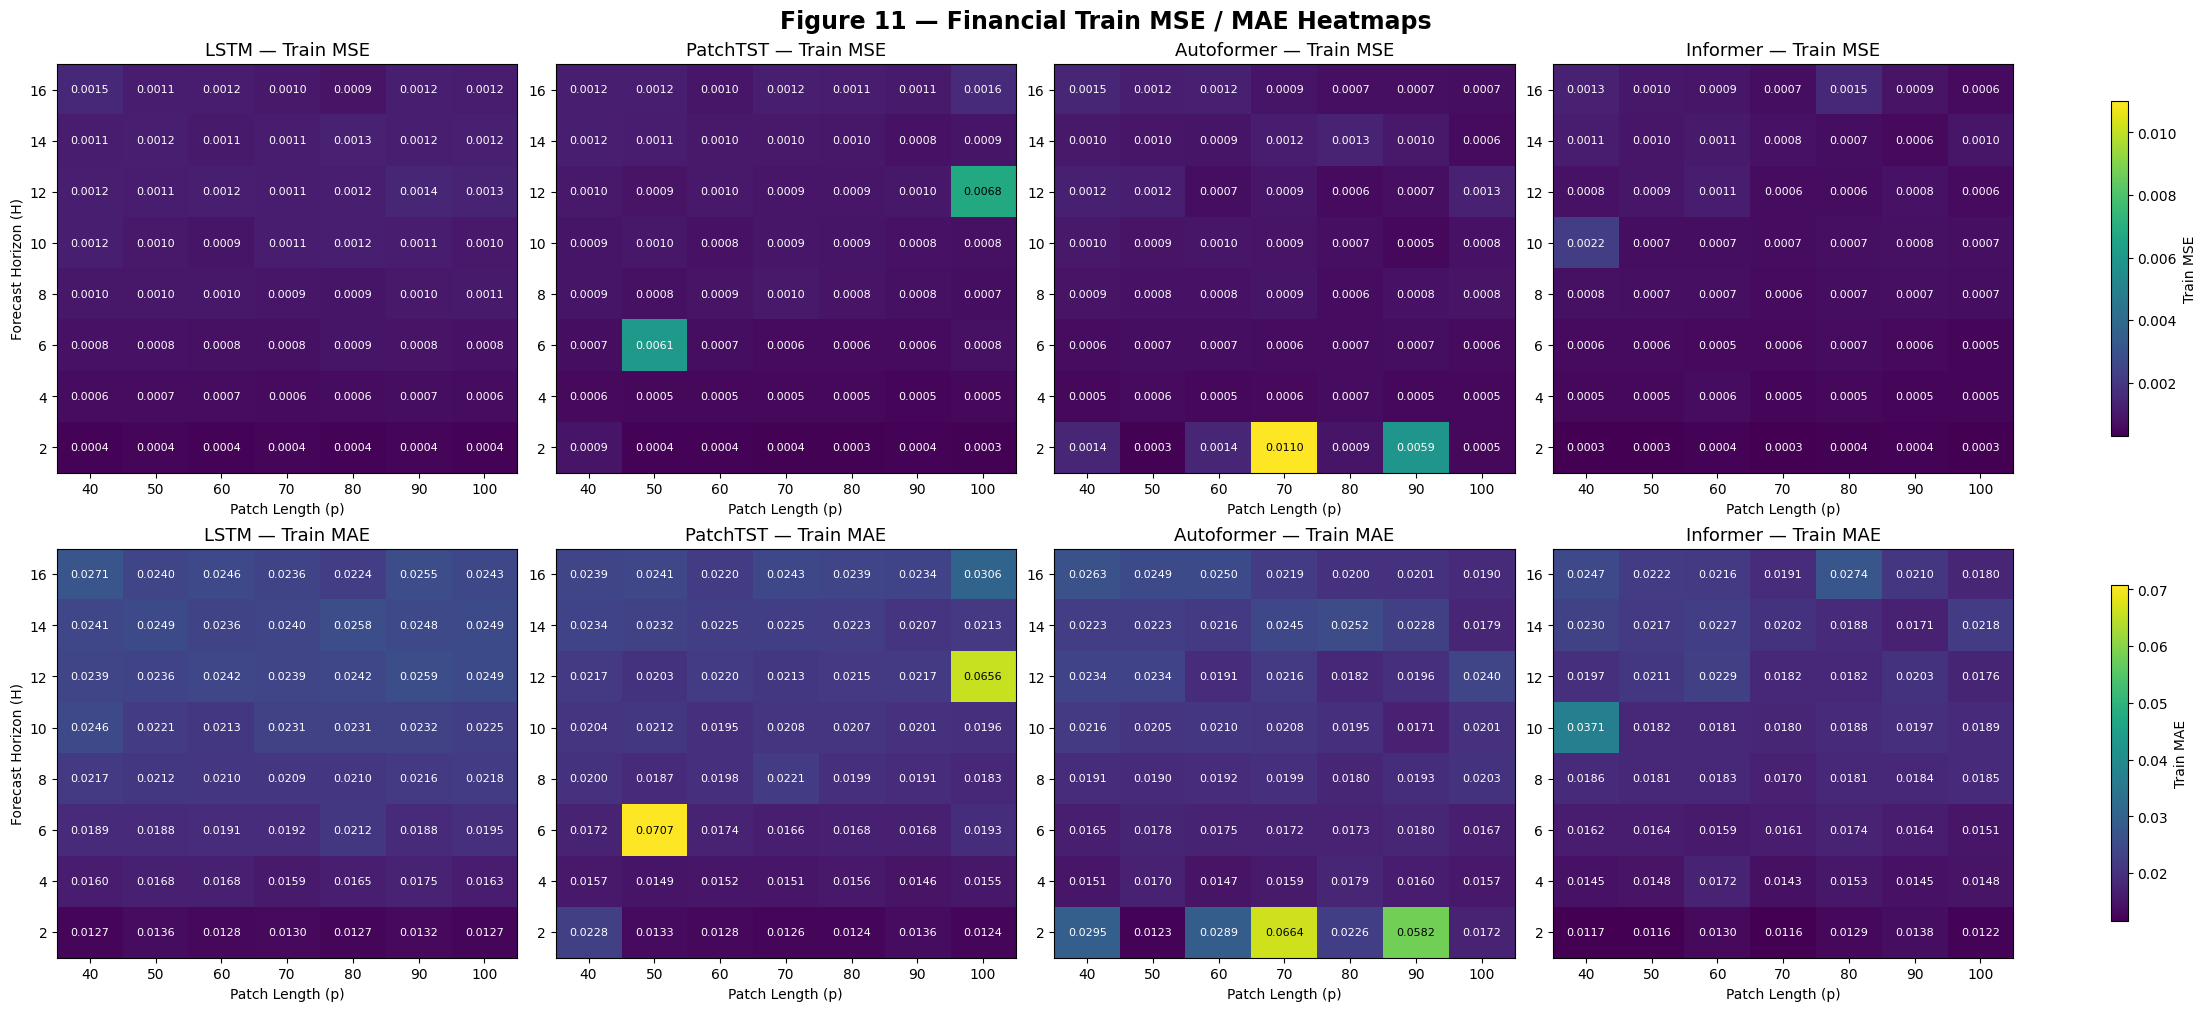

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\results\financial_grid_search_e4000\figure11_financial_train_heatmaps.png


In [6]:
# 1. Chỉ lấy kết quả trên tập Train
train_df = df[df["Set"] == "Train"].copy()

# 2. Tạo figure gồm 2 hàng x 4 cột
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 10),
    constrained_layout=True
)

metrics = ["MSE", "MAE"]

# 3. Vẽ heatmap cho từng metric
for row, metric in enumerate(metrics):

    # Dùng cùng thang màu cho cả 4 mô hình trong cùng 1 metric
    vmin = train_df[metric].min()
    vmax = train_df[metric].max()

    for col, model in enumerate(models):

        # Lọc dữ liệu theo model
        model_df = train_df[
            train_df["Model"] == model
        ]

        # Pivot thành ma trận:
        # hàng = PatchLen, cột = Horizon
        heatmap_data = model_df.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(index=horizons, columns=patches)

        values = heatmap_data.values

        # 4. Vẽ heatmap
        im = axes[row, col].imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        axes[row, col].set_title(
            f"{model} — Train {metric}",
            fontsize=13
        )

        axes[row, col].set_xticks(range(len(patches)), patches)
        axes[row, col].set_yticks(range(len(horizons)), horizons)

        axes[row, col].set_xlabel("Patch Length (p)")

        if col == 0:
            axes[row, col].set_ylabel("Forecast Horizon (H)")
        else:
            axes[row, col].set_ylabel("")

        # 5. Ghi số lên từng ô
        for i in range(values.shape[0]):      # hàng
            for j in range(values.shape[1]):  # cột
                val = values[i, j]

                # Chọn màu chữ để dễ nhìn
                norm_val = (val - vmin) / (vmax - vmin + 1e-12)
                text_color = "white" if norm_val < 0.55 else "black"

                axes[row, col].text(
                    j, i,
                    f"{val:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color
                )

    # 6. Colorbar cho từng hàng metric
    fig.colorbar(
        im,
        ax=axes[row, :],
        label=f"Train {metric}",
        shrink=0.82
    )

fig.suptitle(
    "Figure 11 — Financial Train MSE / MAE Heatmaps",
    fontsize=17,
    fontweight="bold"
)

# 7. Lưu hình
output_path = RESULTS_DIR / "figure11_financial_train_heatmaps.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)

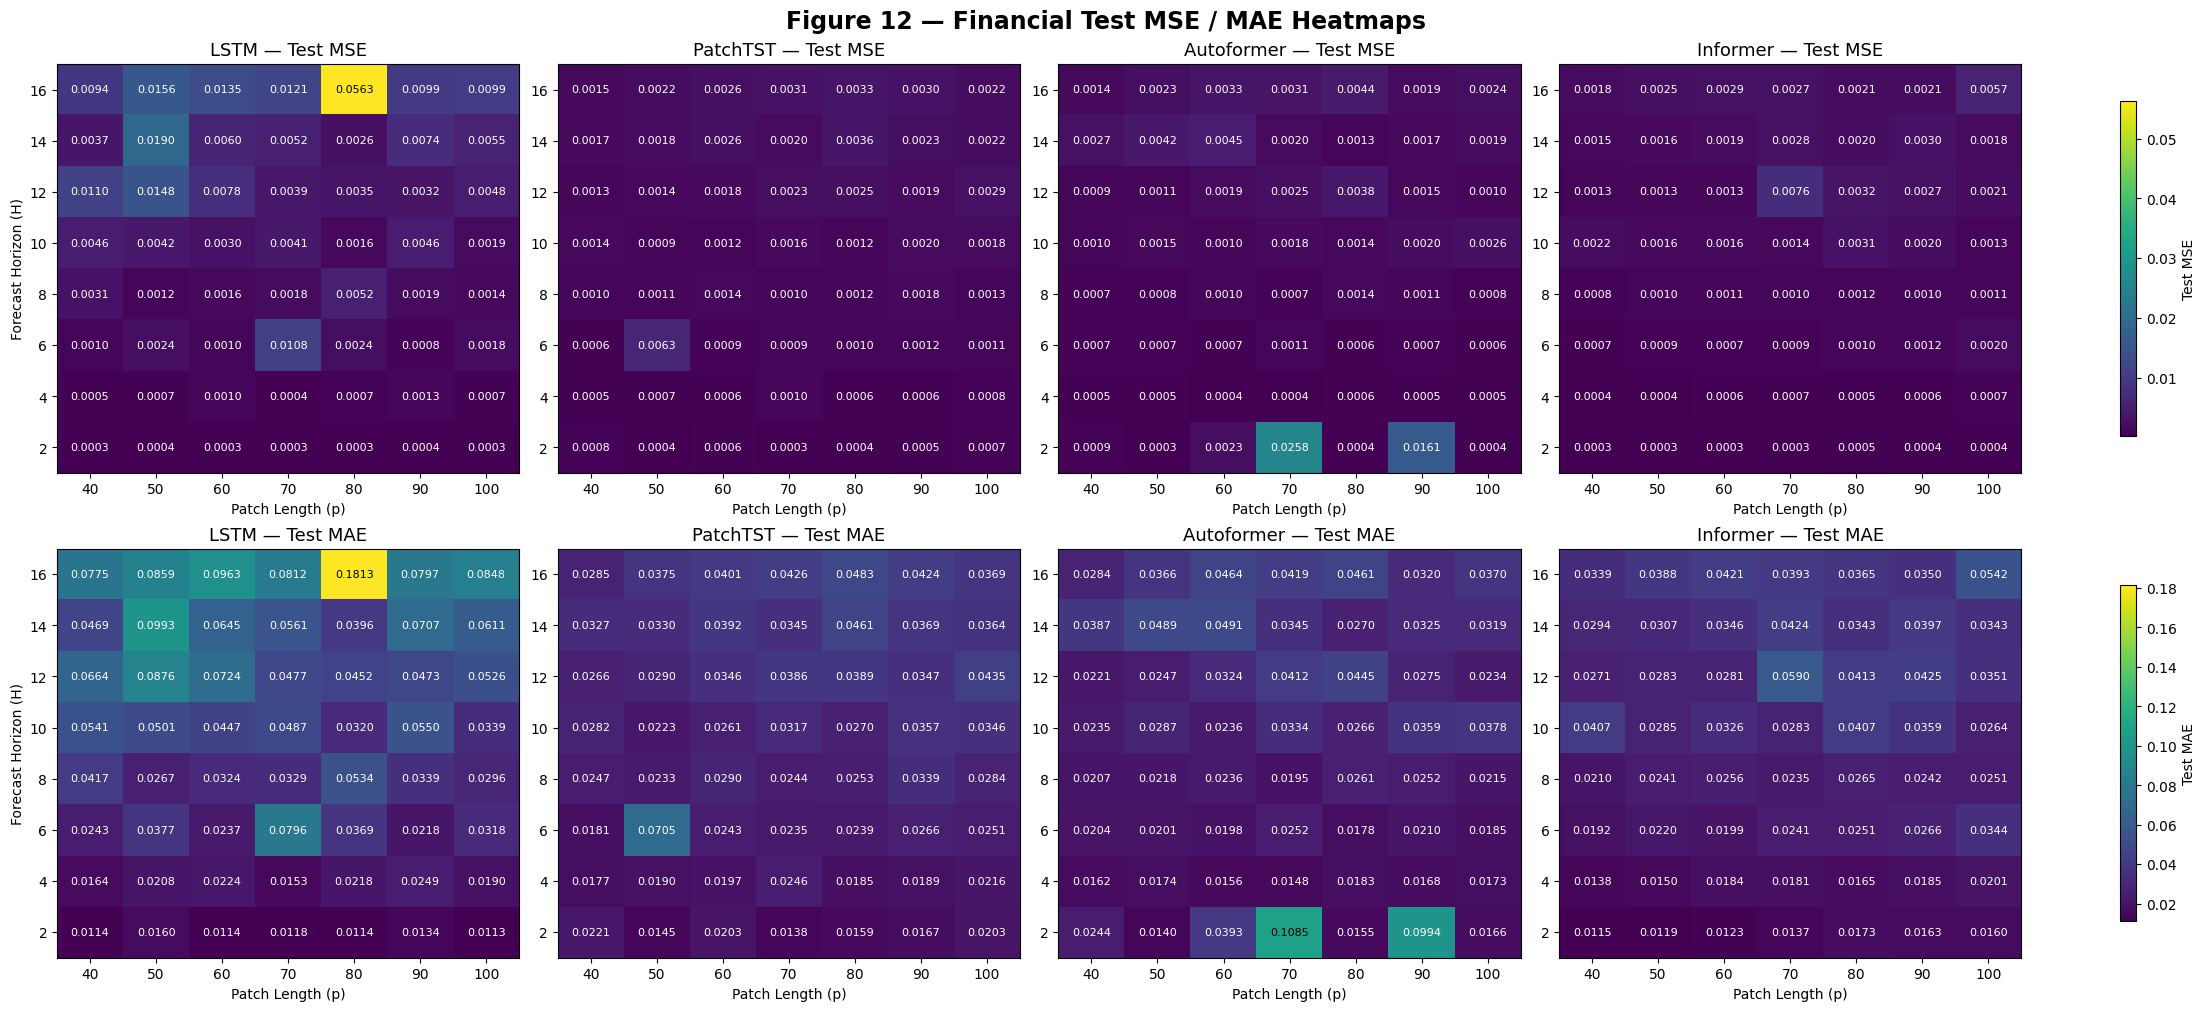

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\results\financial_grid_search_e4000\figure12_financial_test_heatmaps.png


In [7]:
# 1. Chỉ lấy kết quả trên tập Test
test_df = df[df["Set"] == "Test"].copy()

# Kiểm tra dữ liệu Test
assert len(test_df) == 224
assert test_df[["MSE", "MAE"]].notna().all().all()

# 2. Tạo figure gồm 2 hàng x 4 cột
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(22, 10),
    constrained_layout=True
)

# 3. Vẽ heatmap cho MSE và MAE
for row, metric in enumerate(metrics):

    # Thang màu chung giữa 4 mô hình
    vmin = test_df[metric].min()
    vmax = test_df[metric].max()

    for col, model in enumerate(models):

        ax = axes[row, col]

        # Lọc dữ liệu theo mô hình
        model_df = test_df[
            test_df["Model"] == model
        ]

        # Hàng = Forecast Horizon
        # Cột = Patch Length
        heatmap_data = model_df.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(
            index=horizons,
            columns=patches
        )

        values = heatmap_data.to_numpy()

        # Kiểm tra ma trận 8 x 7
        assert values.shape == (8, 7)
        assert np.isfinite(values).all()

        # 4. Vẽ heatmap
        im = ax.imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(
            f"{model} — Test {metric}",
            fontsize=13
        )

        ax.set_xticks(range(len(patches)), patches)
        ax.set_yticks(range(len(horizons)), horizons)

        ax.set_xlabel("Patch Length (p)")

        if col == 0:
            ax.set_ylabel("Forecast Horizon (H)")

        # 5. Hiển thị giá trị trong từng ô
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):

                val = values[i, j]

                norm_val = (
                    (val - vmin)
                    / (vmax - vmin + 1e-12)
                )

                text_color = (
                    "white" if norm_val < 0.55
                    else "black"
                )

                ax.text(
                    j, i,
                    f"{val:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color
                )

    # 6. Colorbar chung cho cả hàng
    fig.colorbar(
        im,
        ax=axes[row, :],
        label=f"Test {metric}",
        shrink=0.82
    )

# 7. Tiêu đề
fig.suptitle(
    "Figure 12 — Financial Test MSE / MAE Heatmaps",
    fontsize=17,
    fontweight="bold"
)

# 8. Lưu hình
output_path = (
    RESULTS_DIR / "figure12_financial_test_heatmaps.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)

Truth shape: (524, 32)
Prediction shape: (524, 32)


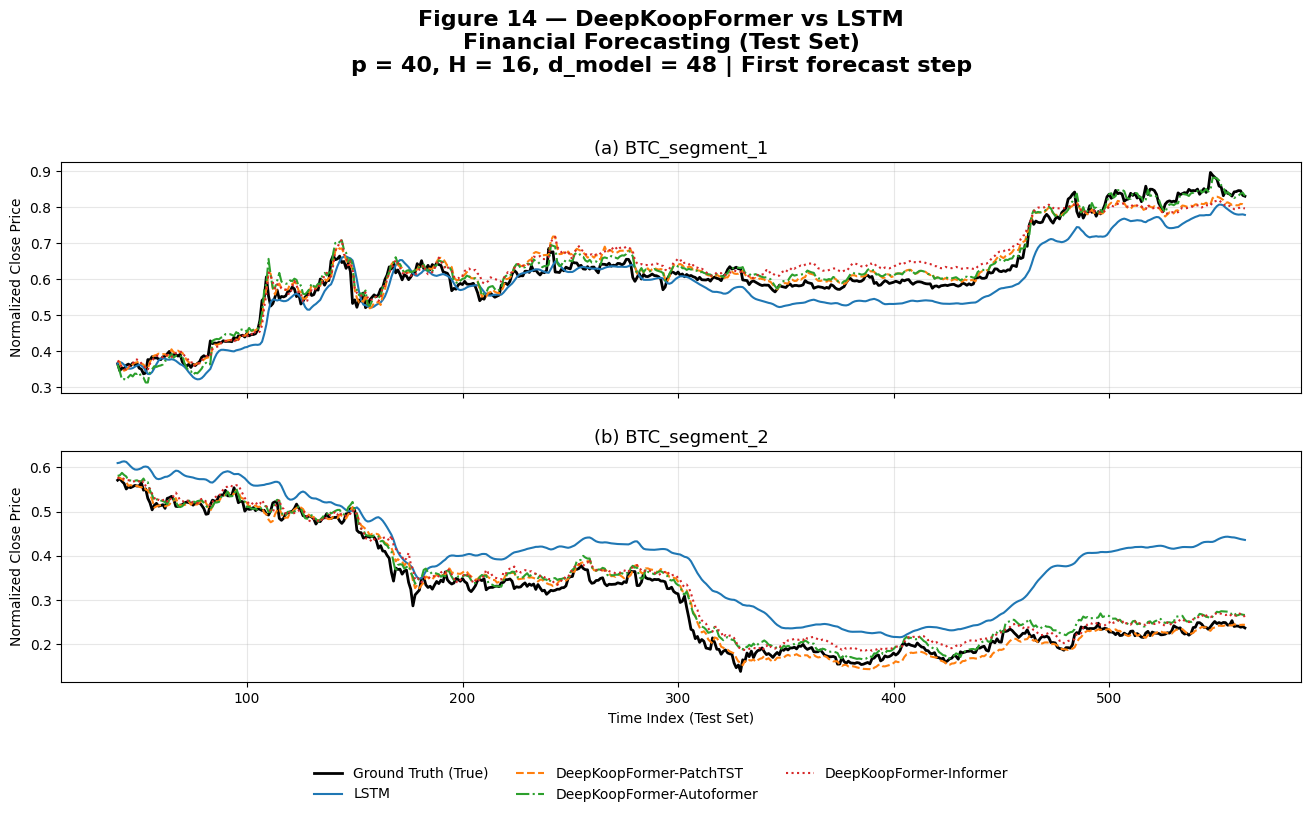

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\results\financial_grid_search_e4000\figure14_financial_test_forecasts.png


In [12]:
# 1. Cấu hình Figure 14
p = 40
H = 16
d_model = 48

channels = bundle["channels"]
num_channels = len(channels)

# 2. Load checkpoints
checkpoints = {}

for model in models:
    path = RESULTS_DIR / (
        f"{model.lower()}_p{p}_h{H}_d{d_model}.pt"
    )

    assert path.exists(), f"Missing checkpoint: {path}"

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    assert ckpt["data_hash"] == bundle["data_hash"]
    assert ckpt["patch_len"] == p
    assert ckpt["horizon"] == H

    checkpoints[model] = ckpt

# 3. Lấy dữ liệu dự báo trên tập Test
truth = checkpoints["LSTM"]["truth_test"].numpy()

predictions = {
    model: checkpoints[model]["pred_test"].numpy()
    for model in models
}

# Kiểm tra các mô hình sử dụng cùng Ground Truth
for model in models:
    np.testing.assert_allclose(
        checkpoints[model]["truth_test"].numpy(),
        truth
    )

    assert predictions[model].shape == truth.shape

print("Truth shape:", truth.shape)
print("Prediction shape:", predictions["PatchTST"].shape)

# 4. Style đồng bộ với các Figure trước
styles = {
    "LSTM": {
        "color": "tab:blue",
        "linestyle": "-",
        "label": "LSTM"
    },
    "PatchTST": {
        "color": "tab:orange",
        "linestyle": "--",
        "label": "DeepKoopFormer-PatchTST"
    },
    "Autoformer": {
        "color": "tab:green",
        "linestyle": "-.",
        "label": "DeepKoopFormer-Autoformer"
    },
    "Informer": {
        "color": "tab:red",
        "linestyle": ":",
        "label": "DeepKoopFormer-Informer"
    }
}

# 5. Tạo Figure
fig, axes = plt.subplots(
    nrows=num_channels,
    ncols=1,
    figsize=(16, 8),
    sharex=True
)

# Trục X: vị trí bước dự báo đầu tiên trong tập Test
sample_indices = np.arange(len(truth))
time_indices = sample_indices + p

for c in range(num_channels):
    ax = axes[c]

    # Flatten theo thứ tự channel-major:
    # [channel_0(t1...tH), channel_1(t1...tH)]
    idx = c * H

    # Ground Truth
    ax.plot(
        time_indices,
        truth[:, idx],
        color="black",
        linewidth=2,
        label="Ground Truth (True)"
    )

    # Dự báo của bốn mô hình
    for model in models:
        ax.plot(
            time_indices,
            predictions[model][:, idx],
            linewidth=1.5,
            **styles[model]
        )

    ax.set_title(
        f"({chr(97 + c)}) {channels[c]}",
        fontsize=13
    )

    ax.set_ylabel("Normalized Close Price")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time Index (Test Set)")

# 6. Tiêu đề và legend chung
fig.suptitle(
    "Figure 14 — DeepKoopFormer vs LSTM\n"
    "Financial Forecasting (Test Set)\n"
    f"p = {p}, H = {H}, d_model = {d_model} | First forecast step",
    fontsize=16,
    fontweight="bold",
    y=0.99
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.015),
    ncol=3,
    frameon=False
)

# Chừa khoảng trống cho tiêu đề và legend
fig.subplots_adjust(
    top=0.80,
    bottom=0.15,
    hspace=0.25
)

# 7. Lưu Figure 14
output_path = RESULTS_DIR / "figure14_financial_test_forecasts.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)

Truth shape: (484, 32)
Prediction shape: (484, 32)


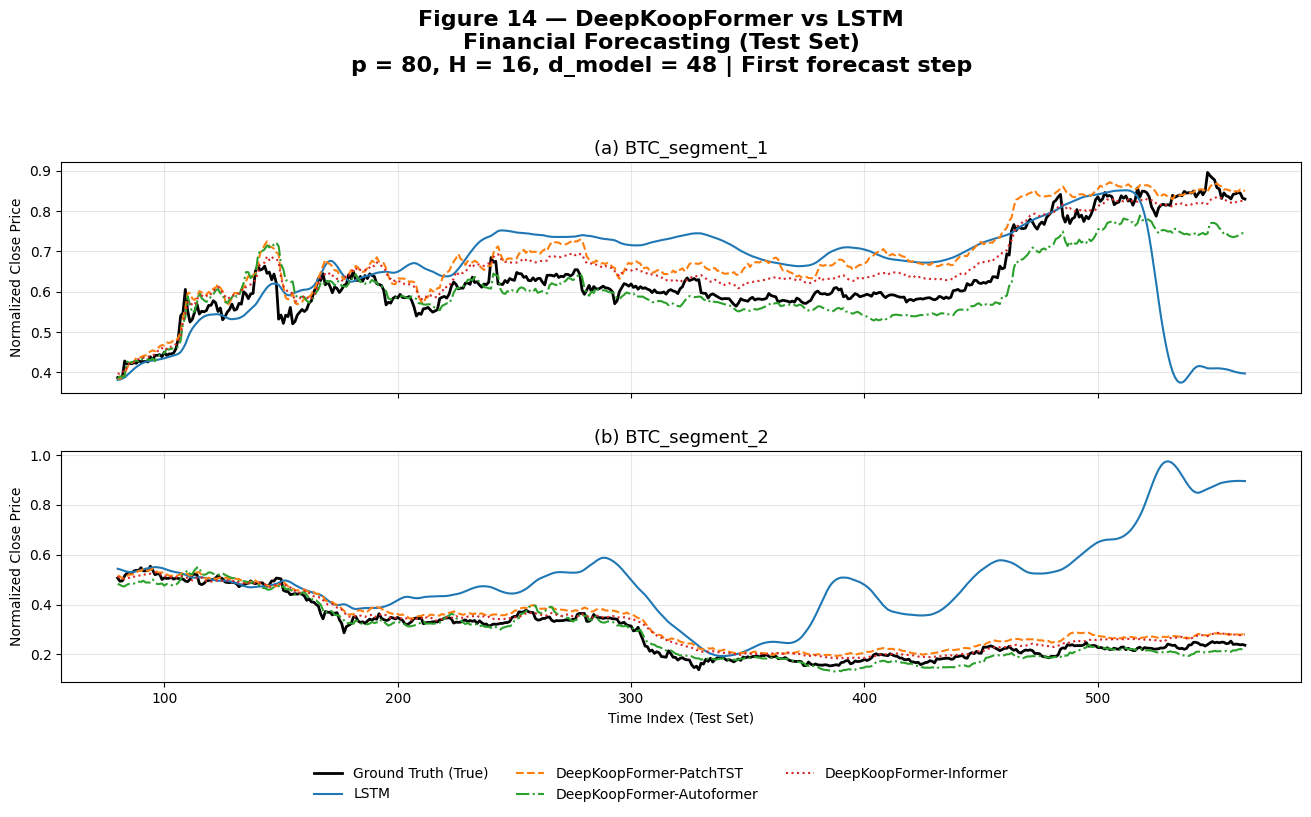

Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\results\financial_grid_search_e4000\figure14_financial_test_forecasts.png


In [ ]:
# 1. Cấu hình Figure 14
p = 80
H = 16
d_model = 48

channels = bundle["channels"]
num_channels = len(channels)

# 2. Load checkpoints
checkpoints = {}

for model in models:
    path = RESULTS_DIR / (
        f"{model.lower()}_p{p}_h{H}_d{d_model}.pt"
    )

    assert path.exists(), f"Missing checkpoint: {path}"

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    assert ckpt["data_hash"] == bundle["data_hash"]
    assert ckpt["patch_len"] == p
    assert ckpt["horizon"] == H

    checkpoints[model] = ckpt

# 3. Lấy dữ liệu dự báo trên tập Test
truth = checkpoints["LSTM"]["truth_test"].numpy()

predictions = {
    model: checkpoints[model]["pred_test"].numpy()
    for model in models
}

# Kiểm tra các mô hình sử dụng cùng Ground Truth
for model in models:
    np.testing.assert_allclose(
        checkpoints[model]["truth_test"].numpy(),
        truth
    )

    assert predictions[model].shape == truth.shape

print("Truth shape:", truth.shape)
print("Prediction shape:", predictions["PatchTST"].shape)

# 4. Style đồng bộ với các Figure trước
styles = {
    "LSTM": {
        "color": "tab:blue",
        "linestyle": "-",
        "label": "LSTM"
    },
    "PatchTST": {
        "color": "tab:orange",
        "linestyle": "--",
        "label": "DeepKoopFormer-PatchTST"
    },
    "Autoformer": {
        "color": "tab:green",
        "linestyle": "-.",
        "label": "DeepKoopFormer-Autoformer"
    },
    "Informer": {
        "color": "tab:red",
        "linestyle": ":",
        "label": "DeepKoopFormer-Informer"
    }
}

# 5. Tạo Figure
fig, axes = plt.subplots(
    nrows=num_channels,
    ncols=1,
    figsize=(16, 8),
    sharex=True
)

# Trục X: vị trí bước dự báo đầu tiên trong tập Test
sample_indices = np.arange(len(truth))
time_indices = sample_indices + p

for c in range(num_channels):
    ax = axes[c]

    # Flatten theo thứ tự channel-major:
    # [channel_0(t1...tH), channel_1(t1...tH)]
    idx = c * H

    # Ground Truth
    ax.plot(
        time_indices,
        truth[:, idx],
        color="black",
        linewidth=2,
        label="Ground Truth (True)"
    )

    # Dự báo của bốn mô hình
    for model in models:
        ax.plot(
            time_indices,
            predictions[model][:, idx],
            linewidth=1.5,
            **styles[model]
        )

    ax.set_title(
        f"({chr(97 + c)}) {channels[c]}",
        fontsize=13
    )

    ax.set_ylabel("Normalized Close Price")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time Index (Test Set)")

# 6. Tiêu đề và legend chung
fig.suptitle(
    "Figure 14 — DeepKoopFormer vs LSTM\n"
    "Financial Forecasting (Test Set)\n"
    f"p = {p}, H = {H}, d_model = {d_model} | First forecast step",
    fontsize=16,
    fontweight="bold",
    y=0.99
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.015),
    ncol=3,
    frameon=False
)

# Chừa khoảng trống cho tiêu đề và legend
fig.subplots_adjust(
    top=0.80,
    bottom=0.15,
    hspace=0.25
)

# 7. Lưu Figure 14
output_path = RESULTS_DIR / "figure14_financial_test_forecasts.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)

In [13]:
# 1. Tổng hợp MSE và MAE theo mô hình và tập dữ liệu
summary = (
    df.groupby(["Set", "Model"])
      .agg(
          Mean_MSE=("MSE", "mean"),
          Median_MSE=("MSE", "median"),
          Mean_MAE=("MAE", "mean"),
          Median_MAE=("MAE", "median")
      )
      .reset_index()
)

# 2. Xếp hạng dựa trên Test MSE trung bình
test_summary = (
    summary[summary["Set"] == "Test"]
    .sort_values("Mean_MSE")
    .reset_index(drop=True)
)

test_summary.insert(
    0,
    "Rank",
    range(1, len(test_summary) + 1)
)

print("=== FINANCIAL MODEL COMPARISON — TEST SET ===")
display(test_summary.round(6))


# 3. So sánh riêng cấu hình Figure 14
fig14_metrics = df[
    (df["PatchLen"] == 80) &
    (df["Horizon"] == 16)
].copy()

fig14_table = fig14_metrics.pivot(
    index="Model",
    columns="Set",
    values=["MSE", "MAE"]
)

# Đặt lại tên các cột cho dễ đọc
fig14_table.columns = [
    f"{set_name}_{metric}"
    for metric, set_name in fig14_table.columns
]

fig14_table = fig14_table.sort_values("Test_MSE")

print("\n=== FIGURE 14 — P=80, H=16 ===")
display(fig14_table.round(6))


# 4. Lưu bảng tổng hợp
output_path = RESULTS_DIR / "financial_mean_metrics_by_model.csv"

summary.to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)

=== FINANCIAL MODEL COMPARISON — TEST SET ===


,Rank,Set,Model,Mean_MSE,Median_MSE,Mean_MAE,Median_MAE
0,1,Test,PatchTST,0.001567,0.001305,0.029492,0.027607
1,2,Test,Informer,0.001577,0.001303,0.028219,0.026868
2,3,Test,Autoformer,0.002190,0.001091,0.030213,0.025198
3,4,Test,LSTM,0.005229,0.002839,0.046361,0.040631



=== FIGURE 14 — P=80, H=16 ===


,Test_MSE,Train_MSE,Test_MAE,Train_MAE
Model,,,,
Informer,0.002147,0.001489,0.036545,0.027369
PatchTST,0.003336,0.001126,0.048274,0.023873
Autoformer,0.004375,0.000734,0.046138,0.020018
LSTM,0.056312,0.000878,0.181281,0.022410



Saved: C:\Users\Win 11 New\Desktop\pa gk\experiments\03_financial\results\financial_grid_search_e4000\financial_mean_metrics_by_model.csv
